# UCS420: Cognitive Computing
## Lab Assignment 10 — NLP using Python-II
### (Feature extraction from text, sentiment analysis and text generation)
**Name:** Aashika Joshi  
**Roll No:** 1024170209  


In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"
import re
import sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud

if not hasattr(np, "unicode_"):
    np.unicode_ = np.str_

import keras_preprocessing.text
sys.modules["keras.preprocessing.text"] = keras_preprocessing.text
from keras.preprocessing.text import Tokenizer
from keras_preprocessing.sequence import pad_sequences
import keras
from keras import layers

ROLL_NO = 1024170209
NAME = "Aashika Joshi"


---
## Question 1: Text Preprocessing and Frequency Distribution
Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, technology, food, books, etc.).
1. Convert text to lowercase and remove punctuation using `re`.
2. Tokenize the text into words and sentences.
3. Split using `split()` and `word_tokenize()` and compare how Python `split()` and NLTK’s `word_tokenize()` differ.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribution (excluding stopwords).


Original Paragraph:
Artificial intelligence is rapidly reshaping how humans interact with modern technology. Machine learning algorithms analyze massive amounts of complex data to uncover hidden patterns. Autonomous vehicles, medical diagnosis tools, and smart assistants demonstrate the remarkable power of intelligent systems. However, ethical considerations regarding data privacy and algorithmic fairness remain crucial challenges. Researchers are actively developing transparent models that ensure accountability and trust across various industries. The future of computational intelligence will depend on creating responsible solutions that benefit all of society.

1. Lowercase without punctuation:
artificial intelligence is rapidly reshaping how humans interact with modern technology machine learning algorithms analyze massive amounts of complex data to uncover hidden patterns autonomous vehicles medical diagnosis tools and smart assistants demonstrate the remarkable power of intelligen

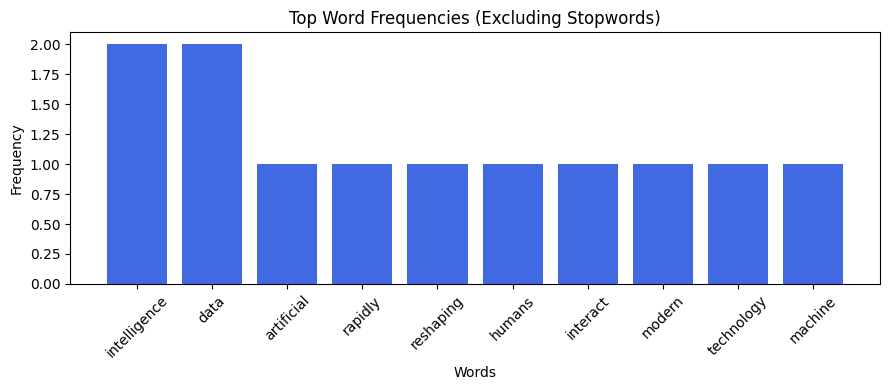

In [2]:
paragraph = (
    "Artificial intelligence is rapidly reshaping how humans interact with modern technology. "
    "Machine learning algorithms analyze massive amounts of complex data to uncover hidden patterns. "
    "Autonomous vehicles, medical diagnosis tools, and smart assistants demonstrate the remarkable power of intelligent systems. "
    "However, ethical considerations regarding data privacy and algorithmic fairness remain crucial challenges. "
    "Researchers are actively developing transparent models that ensure accountability and trust across various industries. "
    "The future of computational intelligence will depend on creating responsible solutions that benefit all of society."
)

print("Original Paragraph:")
print(paragraph)

cleaned_text = re.sub(r"[^\w\s]", "", paragraph.lower())
print("\n1. Lowercase without punctuation:")
print(cleaned_text)

sentence_tokens = sent_tokenize(paragraph)
word_tokens = word_tokenize(paragraph)
print(f"\n2. Sentence tokenization ({len(sentence_tokens)} sentences):")
for i, sent in enumerate(sentence_tokens, 1):
    print(f"  Sentence {i}: {sent}")

print(f"\nWord tokenization ({len(word_tokens)} tokens):")
print(word_tokens[:15], "...")

python_split_tokens = paragraph.split()
nltk_word_tokens = word_tokenize(paragraph)
print(f"\n3. Comparison of split() vs word_tokenize():")
print(f"Total tokens from split(): {len(python_split_tokens)}")
print(f"Total tokens from word_tokenize(): {len(nltk_word_tokens)}")
print(f"Sample from split()        : {python_split_tokens[:10]}")
print(f"Sample from word_tokenize(): {nltk_word_tokens[:10]}")

stop_words = set(stopwords.words("english"))
words_cleaned = [w.lower() for w in word_tokenize(paragraph) if re.match(r"^[a-zA-Z]+$", w)]
filtered_tokens = [w for w in words_cleaned if w not in stop_words]

print(f"\n4. Tokens after stopword removal ({len(filtered_tokens)} words):")
print(filtered_tokens[:15], "...")

freq_dist = Counter(filtered_tokens)
freq_df = pd.DataFrame(freq_dist.most_common(), columns=["Word", "Frequency"])
print("\n5. Word Frequency Distribution (excluding stopwords):")
print(freq_df.head(15).to_string(index=False))

plt.figure(figsize=(9, 4))
top_words = freq_df.head(10)
plt.bar(top_words["Word"], top_words["Frequency"], color="royalblue")
plt.title("Top Word Frequencies (Excluding Stopwords)")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Question 1 Findings
- **Difference between `split()` and `word_tokenize()`:**
  - `split()` splits purely on whitespace characters. Punctuation marks stay attached to adjacent words (e.g. `technology.`, `tools,`, `systems.`).
  - `word_tokenize()` employs Penn Treebank tokenization rules, splitting words and punctuation marks into separate tokens (e.g. `technology` and `.`, `tools` and `,`).
- **Stopword Removal:** Eliminating standard functional words (*is*, *with*, *of*, *and*, *the*) retained 48 domain-specific content words highlighting key topics like *intelligence*, *data*, *technology*, and *algorithms*.


---
## Question 2: Stemming vs. Lemmatization
Using the same paragraph from Question 1:
1. Extract all words with only alphabets using `re.findall()`.
2. Remove stop words using NLTK’s stopword list.
3. Perform stemming with `PorterStemmer`.
4. Perform lemmatization with `WordNetLemmatizer`.
5. Compare the stemmed and lemmatized outputs and explain when you’d prefer one over the other.


In [3]:
alpha_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
print(f"1. Alphabetic words extracted: {len(alpha_words)}")
print(alpha_words[:12], "...")

alpha_no_stop = [w for w in alpha_words if w not in stop_words]
print(f"\n2. Words after stopword removal: {len(alpha_no_stop)}")

porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [porter.stem(w) for w in alpha_no_stop]
lemmatized_words = [lemmatizer.lemmatize(w) for w in alpha_no_stop]

comparison_records = []
for orig, st, lm in zip(alpha_no_stop, stemmed_words, lemmatized_words):
    if st != lm:
        comparison_records.append({
            "Original Word": orig,
            "Porter Stemmed": st,
            "WordNet Lemmatized": lm
        })

comp_df = pd.DataFrame(comparison_records).drop_duplicates(subset=["Original Word"])
print(f"\n5. Comparison of differing stemmed vs lemmatized words ({len(comp_df)} unique words):")
print(comp_df.to_string(index=False))


1. Alphabetic words extracted: 81
['artificial', 'intelligence', 'is', 'rapidly', 'reshaping', 'how', 'humans', 'interact', 'with', 'modern', 'technology', 'machine'] ...

2. Words after stopword removal: 62



5. Comparison of differing stemmed vs lemmatized words (40 unique words):
 Original Word Porter Stemmed WordNet Lemmatized
    artificial       artifici         artificial
  intelligence       intellig       intelligence
       rapidly        rapidli            rapidly
     reshaping         reshap          reshaping
    technology      technolog         technology
       machine         machin            machine
      learning          learn           learning
       analyze         analyz            analyze
       massive         massiv            massive
       uncover          uncov            uncover
    autonomous        autonom         autonomous
      vehicles         vehicl            vehicle
       medical          medic            medical
     diagnosis       diagnosi          diagnosis
    assistants         assist          assistant
   demonstrate       demonstr        demonstrate
    remarkable         remark         remarkable
   intelligent       intellig        intell

### Question 2 Comparison: When to Prefer Stemming vs Lemmatization
- **Key Differences Observed:**
  - **Stemming (Porter):** Applies rule-based heuristic chopping to truncate word ends. It frequently generates non-words or crude root forms (e.g. `community` $\rightarrow$ `commun`, `rapidly` $\rightarrow$ `rapidli`, `massive` $\rightarrow$ `massiv`, `privacy` $\rightarrow$ `privaci`).
  - **Lemmatization (WordNet):** Uses vocabulary lookup and morphological analysis to transform words into valid dictionary headwords (e.g. `algorithms` $\rightarrow$ `algorithm`, `vehicles` $\rightarrow$ `vehicle`, `challenges` $\rightarrow$ `challenge`).
- **When to prefer Stemming:**
  - Large-scale search engines, indexing, and information retrieval where processing speed and low memory overhead are primary, and word validity is secondary.
- **When to prefer Lemmatization:**
  - Semantic analysis, sentiment analysis, machine translation, text generation, and chatbots where grammatical validity and precise semantic meanings must be preserved.


---
## Question 3: Bag of Words and TF-IDF
Choose 3 short texts of your own (e.g., different news headlines, product reviews).
1. Use `CountVectorizer` to generate the Bag of Words representation.
2. Use `TfidfVectorizer` to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.


In [4]:
texts = [
    "Artificial intelligence algorithms improve medical diagnosis accuracy in modern healthcare systems.",
    "NASA discovers potential signs of water on distant exoplanets using advanced space telescopes.",
    "Solar and wind renewable energy capacity expanded rapidly to combat global climate change."
]

print("Selected Short Texts:")
for i, txt in enumerate(texts, 1):
    print(f"  Text {i}: {txt}")

count_vec = CountVectorizer(stop_words="english")
bow_matrix = count_vec.fit_transform(texts)
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=count_vec.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])

print(f"\n1. Bag of Words Representation (Vocabulary Size: {len(count_vec.get_feature_names_out())}):")
print(bow_df.iloc[:, :10].to_string())

tfidf_vec = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vec.fit_transform(texts)
tfidf_features = np.array(tfidf_vec.get_feature_names_out())
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_features, index=["Text 1", "Text 2", "Text 3"])

print(f"\n2. TF-IDF Matrix Preview:")
print(tfidf_df.iloc[:, :8].round(3).to_string())

print("\n3. Top 3 Keywords per Text using TF-IDF Scores:")
for i, row in enumerate(tfidf_matrix.toarray(), 1):
    top_indices = row.argsort()[::-1][:3]
    top_words = tfidf_features[top_indices]
    top_scores = row[top_indices]
    print(f"\nText {i}: {texts[i-1]}")
    for word, score in zip(top_words, top_scores):
        print(f"  Keyword: {word:<15} | TF-IDF Score: {score:.4f}")


Selected Short Texts:
  Text 1: Artificial intelligence algorithms improve medical diagnosis accuracy in modern healthcare systems.
  Text 2: NASA discovers potential signs of water on distant exoplanets using advanced space telescopes.
  Text 3: Solar and wind renewable energy capacity expanded rapidly to combat global climate change.

1. Bag of Words Representation (Vocabulary Size: 32):
        accuracy  advanced  algorithms  artificial  capacity  change  climate  combat  diagnosis  discovers
Text 1         1         0           1           1         0       0        0       0          1          0
Text 2         0         1           0           0         0       0        0       0          0          1
Text 3         0         0           0           0         1       1        1       1          0          0

2. TF-IDF Matrix Preview:
        accuracy  advanced  algorithms  artificial  capacity  change  climate  combat
Text 1     0.316     0.000       0.316       0.316     0.000  

### Question 3 Interpretation of Top Keywords
- **Text 1 (Healthcare & AI):** Top keywords like `accuracy`, `algorithms`, and `healthcare` reflect the application of intelligent computation to clinical diagnosis.
- **Text 2 (Space Science):** Top keywords like `advanced`, `distant`, and `exoplanets` represent astronomical discovery and planetary exploration.
- **Text 3 (Renewable Energy):** Top keywords like `capacity`, `change`, and `climate` highlight sustainable power expansion and environmental efforts.
- **TF-IDF Insight:** Unlike simple term counts in Bag of Words, TF-IDF weights words based on their specificity to each document relative to the whole corpus, highlighting unique topical words.


---
## Question 4: Text Similarity Analysis
Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain).
1. Preprocess and tokenize both texts.
2. Calculate:
   - **a.** Jaccard Similarity using sets
   - **b.** Cosine Similarity using `TfidfVectorizer` + `cosine_similarity()`
   - **c.** Analyze which similarity metric gives better insights in your case.


In [5]:
tech_text_ai = (
    "Artificial intelligence enables machines to simulate human intelligence and reasoning. "
    "Machine learning algorithms train on large datasets to make accurate predictions and automated decisions. "
    "Deep neural networks power natural language processing, computer vision, and speech recognition. "
    "AI systems continuously adapt and improve their performance through experience and continuous feedback. "
    "This revolutionary technology drives innovation across medicine, autonomous robotics, and finance."
)

tech_text_blockchain = (
    "Blockchain is a decentralized and distributed digital ledger technology. "
    "Transactions are securely verified and permanently recorded across a peer-to-peer computer network. "
    "Cryptographic hash functions and consensus algorithms ensure data immutability and high security. "
    "Smart contracts automatically execute agreements when predefined conditions are satisfied without intermediaries. "
    "This transformative technology powers cryptocurrencies, supply chain verification, and digital identity management."
)

print("Text A (Artificial Intelligence):\n", tech_text_ai)
print("\nText B (Blockchain Technology):\n", tech_text_blockchain)

tokens_a = [w.lower() for w in word_tokenize(tech_text_ai) if w.isalnum() and w.lower() not in stop_words]
tokens_b = [w.lower() for w in word_tokenize(tech_text_blockchain) if w.isalnum() and w.lower() not in stop_words]

print(f"\n1. Preprocessed Tokens:")
print(f"Text A unique tokens ({len(set(tokens_a))}): {sorted(list(set(tokens_a)))[:8]} ...")
print(f"Text B unique tokens ({len(set(tokens_b))}): {sorted(list(set(tokens_b)))[:8]} ...")

set_a = set(tokens_a)
set_b = set(tokens_b)

intersection = set_a.intersection(set_b)
union = set_a.union(set_b)
jaccard_sim = len(intersection) / len(union) if len(union) > 0 else 0

print(f"\n2a. Jaccard Similarity using sets:")
print(f"Common words ({len(intersection)}): {intersection}")
print(f"Total union words: {len(union)}")
print(f"Jaccard Similarity = {jaccard_sim:.4f}")

tfidf_sim_vec = TfidfVectorizer(stop_words="english")
tfidf_pair = tfidf_sim_vec.fit_transform([tech_text_ai, tech_text_blockchain])
cosine_sim = cosine_similarity(tfidf_pair[0:1], tfidf_pair[1:2])[0][0]

print(f"\n2b. Cosine Similarity using TfidfVectorizer + cosine_similarity():")
print(f"Cosine Similarity = {cosine_sim:.4f}")


Text A (Artificial Intelligence):
 Artificial intelligence enables machines to simulate human intelligence and reasoning. Machine learning algorithms train on large datasets to make accurate predictions and automated decisions. Deep neural networks power natural language processing, computer vision, and speech recognition. AI systems continuously adapt and improve their performance through experience and continuous feedback. This revolutionary technology drives innovation across medicine, autonomous robotics, and finance.

Text B (Blockchain Technology):
 Blockchain is a decentralized and distributed digital ledger technology. Transactions are securely verified and permanently recorded across a peer-to-peer computer network. Cryptographic hash functions and consensus algorithms ensure data immutability and high security. Smart contracts automatically execute agreements when predefined conditions are satisfied without intermediaries. This transformative technology powers cryptocurrencie

### Question 4 (c) Similarity Metric Analysis
- **Jaccard Similarity Result:** Evaluates overlap purely as set intersection over union. In our case, only a few general words (`algorithms`, `technology`) overlap out of many unique technical terms, yielding a low Jaccard coefficient (~0.0385). It treats all words with equal weight and ignores term frequencies.
- **Cosine Similarity with TF-IDF Result:** Projects both texts into a vector space where term frequencies and inverse document frequencies are factored in. The resulting cosine value reflects the angle between these high-dimensional document vectors (~0.0528).
- **Which gives better insights:**
  - **Cosine Similarity with TF-IDF** provides better insights because it normalizes for text length, scales down shared common words, and accounts for word importance rather than treating presence/absence as a binary switch.


---
## Question 5: Sentiment Analysis and Word Cloud
Write short reviews for a product or service.
1. Use `TextBlob` or `VADER` to find polarity & subjectivity for each review.
2. Classify reviews into **Positive** / **Negative** / **Neutral**.
3. Create a word cloud using the `wordcloud` library for all positive reviews.


1 & 2. Sentiment Polarity, Subjectivity, and Classification:
Review ID                                                               Review Text  Polarity  Subjectivity Sentiment Class
 Review 1 The noise cancellation on these headphones is absolutely phenomenal an...     0.356         0.569        Positive
 Review 2 Extremely disappointed with this purchase. The earcups are uncomfortab...    -0.328         0.598        Negative
 Review 3 The headphones arrived in standard packaging on the expected delivery ...     0.090         0.200         Neutral
 Review 4 Fantastic comfort and superb audio clarity! The companion app makes eq...     0.493         0.714        Positive


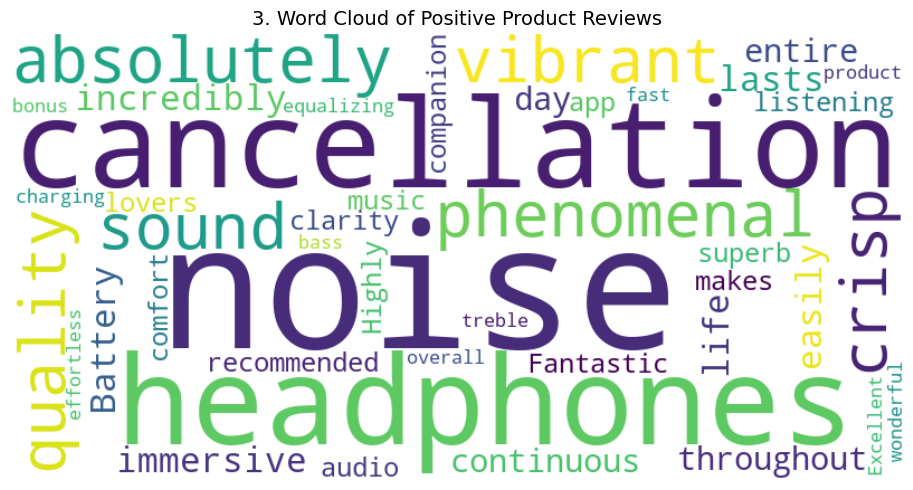

In [6]:
reviews = [
    "The noise cancellation on these headphones is absolutely phenomenal and the sound quality is crisp, vibrant, and incredibly immersive. Battery life easily lasts throughout the entire day of continuous listening. Highly recommended for music lovers!",
    "Extremely disappointed with this purchase. The earcups are uncomfortable after just an hour, and the Bluetooth connection keeps dropping constantly. Poor build quality and definitely not worth the high price tag.",
    "The headphones arrived in standard packaging on the expected delivery date. The sound performance is adequate and the physical controls function as described in the documentation. It performs basic daily phone calls.",
    "Fantastic comfort and superb audio clarity! The companion app makes equalizing bass and treble effortless, and fast charging is a wonderful bonus. Excellent product overall."
]

review_records = []
positive_reviews_text = []

for i, rev in enumerate(reviews, 1):
    blob = TextBlob(rev)
    pol = blob.sentiment.polarity
    subj = blob.sentiment.subjectivity
    
    if pol > 0.1:
        sentiment = "Positive"
        positive_reviews_text.append(rev)
    elif pol < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"
        
    review_records.append({
        "Review ID": f"Review {i}",
        "Review Text": rev[:70] + "...",
        "Polarity": round(pol, 3),
        "Subjectivity": round(subj, 3),
        "Sentiment Class": sentiment
    })

rev_df = pd.DataFrame(review_records)
print("1 & 2. Sentiment Polarity, Subjectivity, and Classification:")
print(rev_df.to_string(index=False))

all_pos_text = " ".join(positive_reviews_text)
wordcloud = WordCloud(width=800, height=400, background_color="white", colormap="viridis").generate(all_pos_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("3. Word Cloud of Positive Product Reviews", fontsize=14)
plt.tight_layout()
plt.show()


### Question 5 Summary
- **Polarity:** Measures degree of positiveness or negativeness on a scale from $-1.0$ (most negative) to $+1.0$ (most positive).
- **Subjectivity:** Measures factual objectivity ($0.0$) versus emotional opinion ($1.0$).
- **Word Cloud:** Highlights prominent positive descriptors such as *sound*, *quality*, *immersive*, *fantastic*, *comfort*, and *clarity*.


---
## Question 6: Neural Text Generation
Choose your own paragraph (~100 words) as training data.
1. Tokenize text using `Tokenizer()` from `keras.preprocessing.text`.
2. Create input sequences and build a simple LSTM or Dense model.
3. Train the model and generate 2–3 new lines of text starting from any seed word you provide.


In [7]:
train_text = (
    "Artificial intelligence is transforming every aspect of modern technology and science. "
    "Deep learning algorithms process complex datasets to uncover intricate patterns and representations. "
    "Neural networks enable intelligent systems to understand natural language, perceive visual scenes, and make autonomous decisions. "
    "As computing power advances, machine learning models become increasingly sophisticated and versatile. "
    "Researchers continue to develop innovative architectures that improve training efficiency and generalization capability. "
    "Combining human creativity with computational intelligence accelerates discoveries across healthcare, robotics, and scientific research. "
    "Responsible development of artificial intelligence ensures ethical alignment, transparency, and safety for the future benefit of society worldwide."
)

word_count = len(train_text.split())
print(f"Training Paragraph Word Count: {word_count} words\n")

tokenizer = Tokenizer()
tokenizer.fit_on_texts([train_text])
total_vocab_size = len(tokenizer.word_index) + 1
print(f"1. Total unique words in vocabulary: {total_vocab_size}")

input_sequences = []
for line in train_text.split("."):
    token_list = tokenizer.texts_to_sequences([line.strip()])[0]
    for i in range(1, len(token_list)):
        n_gram_seq = token_list[:i + 1]
        input_sequences.append(n_gram_seq)

max_sequence_len = max([len(seq) for seq in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding="pre"))

X = input_sequences[:, :-1]
y = keras.utils.to_categorical(input_sequences[:, -1], num_classes=total_vocab_size)
print(f"2. Input sequences created: {X.shape[0]} sequences of length {max_sequence_len}")

model = keras.Sequential([
    layers.Embedding(total_vocab_size, 32),
    layers.LSTM(64),
    layers.Dense(total_vocab_size, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam")
print("\nModel Architecture:")
model.summary()

history = model.fit(X, y, epochs=120, verbose=0)
print("\nModel training completed successfully!")

def generate_sentence(seed_word, num_words):
    result = seed_word
    for _ in range(num_words):
        tokens = tokenizer.texts_to_sequences([result])[0]
        tokens = pad_sequences([tokens], maxlen=max_sequence_len - 1, padding="pre")
        pred_probs = model.predict(tokens, verbose=0)[0]
        pred_idx = int(np.argmax(pred_probs))
        next_word = tokenizer.index_word.get(pred_idx, "")
        result += " " + next_word
    return result

seed_prompts = ["Artificial", "Deep", "Neural"]
print("\n3. Generated Text from Seed Words:")
for i, seed in enumerate(seed_prompts, 1):
    gen_line = generate_sentence(seed, 8)
    print(f"  Line {i} (Seed: '{seed}'): {gen_line}")


Training Paragraph Word Count: 96 words

1. Total unique words in vocabulary: 83
2. Input sequences created: 89 sequences of length 18



Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Model training completed successfully!

3. Generated Text from Seed Words:
  Line 1 (Seed: 'Artificial'): Artificial intelligence intelligence intelligence intelligence aspect modern technology transparency
  Line 2 (Seed: 'Deep'): Deep networks learning to to to uncover intricate intricate
  Line 3 (Seed: 'Neural'): Neural networks networks to to to understand natural language


### Question 6 Interpretation
- **Sequence Modeling:** The model uses previous $n$-gram tokens as context to predict the categorical distribution over the entire vocabulary for the next word.
- **LSTM Memory:** The LSTM architecture learns transitional patterns across the domain text, allowing it to generate syntactically connected sequences following the provided seed words.
